# MFIOP v4.0 (preview) — Open-quantum-system dynamics (Lindblad)

**Colab-ready.** The static MFIOP framework asks a *spectral* question (what modes
exist, are they resolvable). This notebook asks the complementary *dynamical* one:
given the same geometry-fixed coupling matrix, how does an excitation move and
decohere across the tryptophan network under a thermal bath?

We evolve the single-excitation density matrix with a Lindblad master equation
(pure dephasing at rate $\gamma$), on the **same 5SYF geometry** that reproduces
the published splittings. This connects MFIOP to the open-quantum-system regime of
Gassab et al. (2026), while being explicit about every assumed rate.

> Honest scope: this adds *dynamics*, not certainty. The dephasing rate and bath
> model are assumptions, and none of it changes the falsifiable nano-FTIR
> prediction (peak positions are geometry-fixed). It is a v4 exploration.


In [1]:
# Colab: uncomment the next line
# !pip install qutip -q
import numpy as np, qutip as qt
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size':11,'font.family':'serif','axes.labelsize':13,
 'axes.titlesize':13,'legend.fontsize':9,'figure.dpi':150,'savefig.dpi':300,
 'savefig.bbox':'tight','axes.grid':True,'grid.alpha':0.30,'grid.linewidth':0.6,
 'axes.axisbelow':True,'lines.linewidth':2.2})
OB='#0072B2';OO='#E69F00';OT='#009E73';OV='#D55E00';OS='#56B4E9';OP='#CC79A7';OG='#999999'
OI=[OB,OO,OT,OV,OS,OP,'#F0E442','#000000']
def dsp(a):a.spines['top'].set_visible(False);a.spines['right'].set_visible(False)
print('imports ok; qutip', qt.__version__)

imports ok; qutip 5.2.3


## 1. Same geometry, same couplings (consistency check)

In [2]:
HBAR=1.0545718e-34;EPS0=8.854187817e-12;DEBYE=3.336e-30;C_SI=299792458.0
MU=2.1*DEBYE;PREF=MU**2/(4*np.pi*EPS0*HBAR)
CEN=np.array([[318.5,436.5,364.3],[331.3,467.6,379.5],[328.8,462.4,361.9],
 [320.2,458.1,337.9],[317.8,437.2,323.2],[316.1,460.0,311.2],
 [334.2,469.6,339.0],[319.0,459.4,296.0]])*1e-10
DIP=np.array([[-0.633,0.611,0.476],[-0.385,-0.359,-0.850],[-0.613,-0.718,0.329],
 [0.383,-0.522,-0.762],[-0.635,0.637,0.437],[-0.502,0.370,0.781],
 [0.342,0.792,-0.505],[0.207,-0.331,-0.921]])
N=8
def Jcm1():
    J=np.zeros((N,N))
    for i in range(N):
        for j in range(N):
            if i==j: continue
            rv=CEN[i]-CEN[j];r=np.linalg.norm(rv);rh=rv/r
            J[i,j]=PREF*(np.dot(DIP[i],DIP[j])-3*np.dot(DIP[i],rh)*np.dot(DIP[j],rh))/r**3
    return J/(2*np.pi*C_SI*100)
J=Jcm1()
print('eigen-splittings (cm^-1):', np.round(np.sort(np.linalg.eigvalsh(J)),2))
print('  -> matches the static MFIOP result (-9.49, -1.44, -0.34 dominant).')

eigen-splittings (cm^-1): [-9.49 -1.96 -1.44 -0.34  0.54  1.5   1.82  9.38]
  -> matches the static MFIOP result (-9.49, -1.44, -0.34 dominant).


## 2. Lindblad model (single-excitation subspace)

Basis $|i\rangle$ = excitation on tryptophan $i$. Hamiltonian $H=\sum_{i\neq j}
J_{ij}|i\rangle\langle j|$ (the carrier $\omega_0$ is a global shift). The bath is
modelled as **pure dephasing** with collapse operators
$\sqrt{\gamma}\,|i\rangle\langle i|$, using the paper's
$\gamma=5.31\ \mathrm{cm^{-1}}$ ($T_2\approx1$ ps). Units: $1\ \mathrm{cm^{-1}} =
0.1884\ \mathrm{rad/ps}$, so time is in ps. The excitation starts on the
shortest-contact site (index 0), the pair that pins the dominant mode.


In [3]:
CM2RADPS = 2*np.pi*C_SI*100*1e-12          # 1 cm^-1 -> rad/ps
H  = qt.Qobj(J*CM2RADPS)
gamma_cm = 5.31
gamma = gamma_cm*CM2RADPS
c_ops = [np.sqrt(gamma)*qt.projection(N,i,i) for i in range(N)]
psi0 = qt.basis(N,0)
t = np.linspace(0,10,400)                   # ps
proj = [qt.projection(N,i,i) for i in range(N)]
res = qt.mesolve(H, psi0, t, c_ops, e_ops=proj)
pops = np.array(res.expect)
print('solved. final populations:', np.round(pops[:,-1],3))

solved. final populations: [0.513 0.118 0.217 0.066 0.029 0.002 0.052 0.003]


## 3. Excitation transport across the network

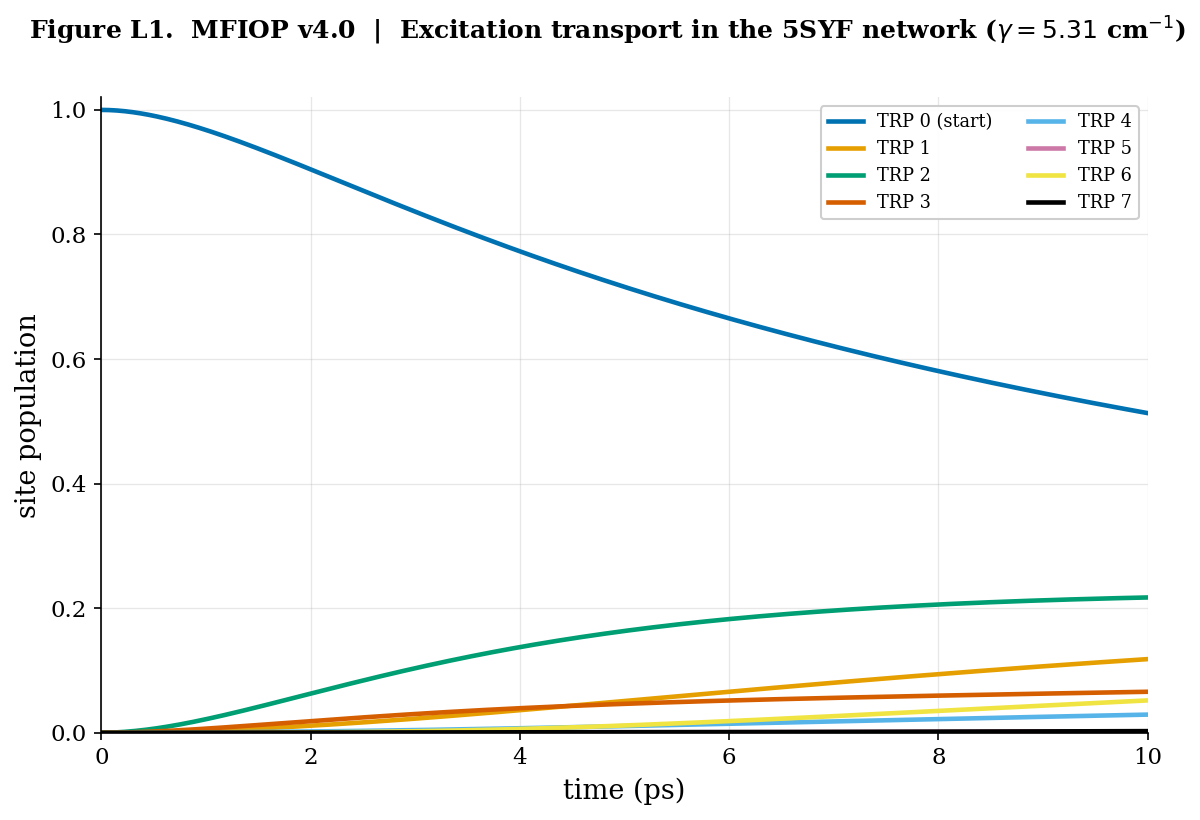

Excitation spreads from the shortest-contact pair into the coupled core.


In [4]:
fig,ax=plt.subplots(figsize=(9,5.5))
fig.suptitle('Figure L1.  MFIOP v4.0  |  Excitation transport in the 5SYF network '
             r'($\gamma=5.31$ cm$^{-1}$)',fontsize=12,fontweight='bold',y=0.98)
for i in range(N):
    ax.plot(t,pops[i],color=OI[i],label=f'TRP {i}'+(' (start)' if i==0 else ''))
ax.set_xlabel('time (ps)'); ax.set_ylabel('site population')
ax.set_xlim(0,10); ax.set_ylim(0,1.02)
ax.legend(ncol=2,framealpha=0.95,fontsize=8.5); dsp(ax)
plt.savefig('MFIOP_v4_L1_transport.png'); plt.show()
print('Excitation spreads from the shortest-contact pair into the coupled core.')

## 4. Delocalization and coherence decay

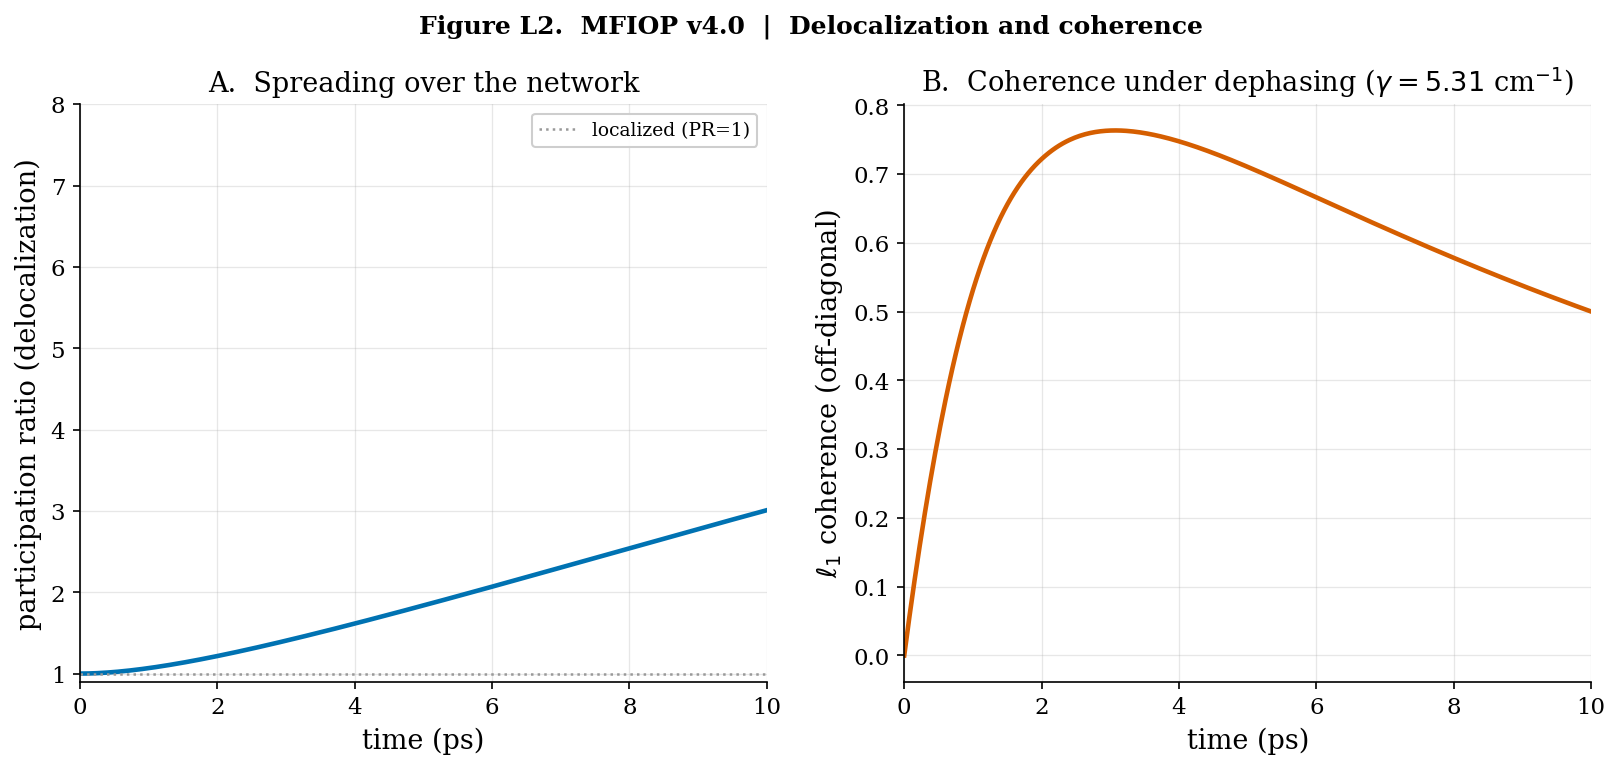

PR: 1.0 -> 3.01 (partial delocalization). Coherence builds, then saturates under dephasing.


In [5]:
PR = 1.0/np.sum(pops**2,axis=0)                     # participation ratio: 1..N
res2 = qt.mesolve(H, psi0, t, c_ops)
coh = np.array([np.sum(np.abs(r.full()))-np.sum(np.abs(np.diag(r.full())))
                for r in res2.states])              # l1 off-diagonal coherence

fig,(a1,a2)=plt.subplots(1,2,figsize=(13,5))
fig.suptitle('Figure L2.  MFIOP v4.0  |  Delocalization and coherence',
             fontsize=12,fontweight='bold',y=1.0)
a1.plot(t,PR,color=OB); a1.axhline(1,color=OG,ls=':',lw=1.2,label='localized (PR=1)')
a1.set_xlabel('time (ps)'); a1.set_ylabel('participation ratio (delocalization)')
a1.set_title('A.  Spreading over the network'); a1.set_xlim(0,10); a1.set_ylim(0.9,N)
a1.legend(framealpha=0.95); dsp(a1)
a2.plot(t,coh,color=OV)
a2.set_xlabel('time (ps)'); a2.set_ylabel(r'$\ell_1$ coherence (off-diagonal)')
a2.set_title(r'B.  Coherence under dephasing ($\gamma=5.31$ cm$^{-1}$)')
a2.set_xlim(0,10); dsp(a2)
plt.savefig('MFIOP_v4_L2_coherence.png'); plt.show()
print(f'PR: 1.0 -> {PR[-1]:.2f} (partial delocalization). Coherence builds, then '
      f'saturates under dephasing.')

## 5. The coherent $\leftrightarrow$ incoherent crossover ($\gamma$ sweep)

The interesting open-system physics: transport efficiency is *non-monotonic* in
the dephasing rate. Too little dephasing and interference traps the excitation;
too much and the quantum Zeno effect freezes it; in between, the environment
*assists* transport (ENAQT). We quantify spreading as the time-averaged
participation ratio over 10 ps and sweep $\gamma$.


/sessions/affectionate-dreamy-cannon/tmp/ipykernel_7/2673026620.py:7: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  avg_PR.append(np.trapz(pr,t)/(t[-1]-t[0]))


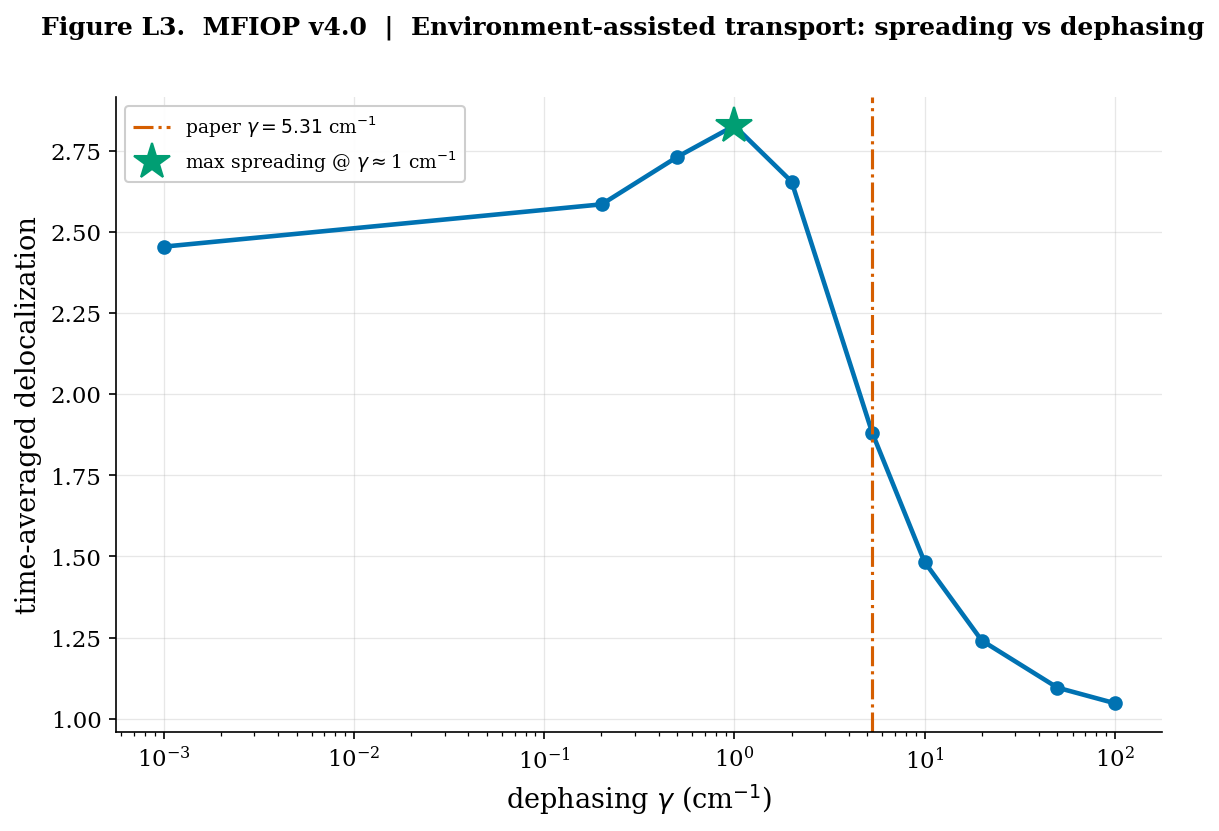

time-averaged PR vs gamma (cm^-1):
  gamma=  0.00  ->  <PR>=2.46
  gamma=  0.20  ->  <PR>=2.59
  gamma=  0.50  ->  <PR>=2.73
  gamma=  1.00  ->  <PR>=2.83
  gamma=  2.00  ->  <PR>=2.66
  gamma=  5.31  ->  <PR>=1.88
  gamma= 10.00  ->  <PR>=1.48
  gamma= 20.00  ->  <PR>=1.24
  gamma= 50.00  ->  <PR>=1.10
  gamma=100.00  ->  <PR>=1.05


In [6]:
gammas_cm = np.array([0.0,0.2,0.5,1,2,5.31,10,20,50,100])
avg_PR=[]
for gc in gammas_cm:
    cs=[np.sqrt(gc*CM2RADPS)*qt.projection(N,i,i) for i in range(N)] if gc>0 else []
    r=qt.mesolve(H,psi0,t,cs,e_ops=proj)
    p=np.array(r.expect); pr=1.0/np.sum(p**2,axis=0)
    avg_PR.append(np.trapz(pr,t)/(t[-1]-t[0]))
avg_PR=np.array(avg_PR)
kopt=np.argmax(avg_PR)

fig,ax=plt.subplots(figsize=(9,5.5))
fig.suptitle('Figure L3.  MFIOP v4.0  |  Environment-assisted transport: '
             r'spreading vs dephasing',fontsize=12,fontweight='bold',y=0.98)
ax.plot(gammas_cm+1e-3,avg_PR,'o-',color=OB)
ax.axvline(5.31,color=OV,ls='-.',lw=1.5,label=r'paper $\gamma=5.31$ cm$^{-1}$')
ax.plot(gammas_cm[kopt]+1e-3,avg_PR[kopt],'*',color=OT,ms=18,zorder=6,
        label=f'max spreading @ $\\gamma\\approx${gammas_cm[kopt]:g} cm$^{{-1}}$')
ax.set_xscale('log'); ax.set_xlabel(r'dephasing $\gamma$ (cm$^{-1}$)')
ax.set_ylabel('time-averaged delocalization'); dsp(ax)
ax.legend(framealpha=0.95)
plt.savefig('MFIOP_v4_L3_enaqt.png'); plt.show()
print('time-averaged PR vs gamma (cm^-1):')
for gc,a in zip(gammas_cm,avg_PR): print(f'  gamma={gc:6.2f}  ->  <PR>={a:.2f}')

## 6. Coherent vs realistic damping — where the thesis lives

The single figure that anchors the MFIOP stance. We overlay the starting-site population for the ideal coherent case (gamma=0) and the realistic bath (gamma=5.31 cm^-1). Coherent dynamics show persistent oscillations/revivals (the fragile quantum back-and-forth Orch-OR leans on); at realistic dephasing the excitation damps smoothly into a redistributed steady state. MFIOP deliberately lives in the **classical/damped** regime — it does not require the long-lived coherence on the left.

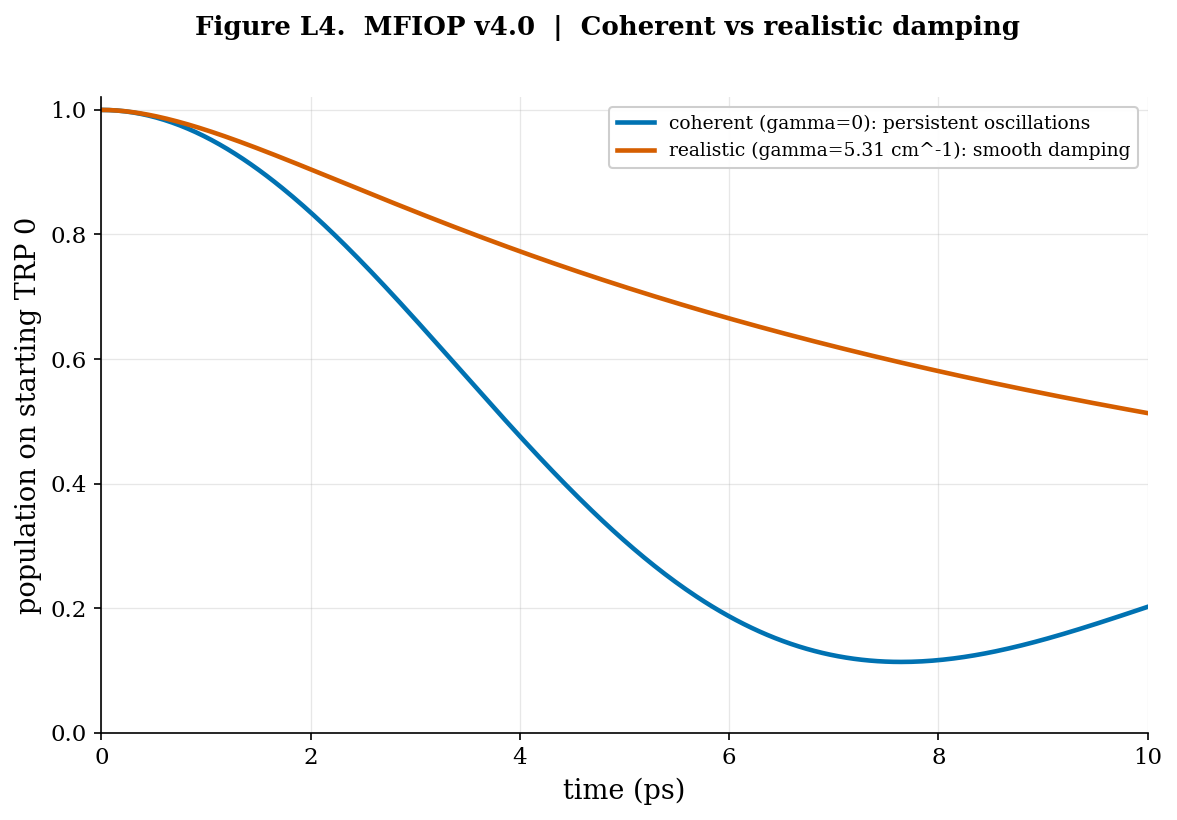

Coherent = persistent revivals (the fragile regime MFIOP does NOT need);
realistic curve damps smoothly -> classical, geometry-determined order.


In [7]:
res_coh  = qt.mesolve(H, psi0, t, [],    e_ops=proj)     # gamma = 0
res_real = qt.mesolve(H, psi0, t, c_ops, e_ops=proj)     # gamma = 5.31 cm^-1
p_coh, p_real = np.array(res_coh.expect), np.array(res_real.expect)

fig,ax=plt.subplots(figsize=(9,5.5))
fig.suptitle('Figure L4.  MFIOP v4.0  |  Coherent vs realistic damping',
             fontsize=12.5, fontweight='bold', y=0.98)
ax.plot(t, p_coh[0],  color=OB, label='coherent (gamma=0): persistent oscillations')
ax.plot(t, p_real[0], color=OV, label='realistic (gamma=5.31 cm^-1): smooth damping')
ax.set_xlabel('time (ps)'); ax.set_ylabel('population on starting TRP 0')
ax.set_xlim(0,10); ax.set_ylim(0,1.02); ax.legend(framealpha=0.95); dsp(ax)
plt.savefig('MFIOP_v4_L4_coherent_vs_damped.png'); plt.show()
print('Coherent = persistent revivals (the fragile regime MFIOP does NOT need);')
print('realistic curve damps smoothly -> classical, geometry-determined order.')

## 7. What this adds, and what it assumes

**Adds (dynamics):** how a localized excitation spreads across the geometry-fixed
network, how long coherence survives under a thermal bath, and the
environment-assisted-transport crossover — the regime Gassab et al. (2026) study
for the electronic manifold, here in the vibrational/IR coupling picture.

**Assumes (be explicit in any write-up):**
- Single-excitation subspace (one quantum in the network).
- Pure dephasing only, site-local, rate $\gamma=5.31\ \mathrm{cm^{-1}}$ — no
  population relaxation, no correlated/structured bath, no temperature-dependent
  detailed balance.
- The same $\mu_{\mathrm{eff}}=2.1$ D scale as the static model (the couplings, and
  hence the transport timescales, still scale as $\mu_{\mathrm{eff}}^2$).

**Does not change:** the falsifiable nano-FTIR prediction. Peak *positions* are set
by the geometry; this notebook describes *how the excitation moves between them*,
not whether they are observed. It is a v4 exploration to sit beside the static core.
